# 06 — Ekstraksi Fitur Warna, Tekstur GLCM, dan Morfologi Mask

## Ringkasan utama

Notebook ini mendokumentasikan **ekstraksi fitur tetap (fixed-length)** untuk seluruh kohort berpasangan **2.226 citra** EBHI-SEG (train 1.535, val 372, test 319) menggunakan **empat komparator segmentasi beku**: `otsu_M0`, `otsu_M2`, `k4_M0` (konfigurasi terpilih), dan `k4_M1`.

Tiga set fitur kanonik didefinisikan:

- **Set A — appearance (10 fitur):** rerata dan simpangan baku populasi kanal CIE Lab (`L*`, `a*`, `b*`) serta empat properti GLCM yang dirata-ratakan atas delapan pasangan jarak–sudut. Set A dihitung dari seluruh piksel citra RGB.
- **Set B — morfologi mask (19 fitur):** empat deskriptor global mask dan ringkasan rerata/simpangan baku populasi/median untuk lima ukuran per komponen (`area_rel`, `perimeter_rel`, `circularity`, `eccentricity`, `solidity`).
- **Set C — gabungan (29 fitur):** konkatenasi A dan B untuk setiap komparator.

Notebook juga membangun **A_seg (10 fitur)** dan **C_seg (29 fitur)** khusus untuk `k4_M0`. A_seg menghitung fitur warna dan GLCM hanya pada piksel mask prediksi; C_seg menggabungkan A_seg dengan B. Tujuannya bukan mengganti A/C secara otomatis, melainkan mengukur sensitivitas fitur terhadap batas objek dan menyediakan pembanding yang tidak membaca *reference mask*.

**Batas ilmiah:** fitur citra tidak pernah membaca *reference mask*; fitur morfologi dan A_seg hanya memakai mask prediksi dari artefak `train` yang sudah dibekukan. Tidak ada pelatihan ulang, *tuning*, atau evaluasi `test` di sini.


## Konteks, kontrak fitur, dan artefak kanonik

**Pertanyaan:** bagaimana mengubah citra histopatologi dan mask segmentasinya menjadi vektor fitur numerik yang konsisten, terdokumentasi, dan siap dipakai oleh klasifikasi SVM A/B/C pada tahap berikutnya?

### Aturan yang dipertahankan

- `split_manifest.csv` adalah otoritas kohort; checksum *raw-byte*-nya diverifikasi sebelum dan sesudah eksekusi.
- **Set A** dihitung dari citra RGB asli (`uint8`). Konversi Lab memakai kontrak yang sama dengan segmentasi: RGB `float32 / 255` lalu `COLOR_RGB2LAB`.
- **GLCM:** kuantisasi tetap 16 level dengan interval `gray // 16`, jarak `(1, 2)`, sudut `0°, 45°, 90°, 135°`, `symmetric=True`, `normed=True`; nilai akhir adalah rerata atas delapan pasangan. Korelasi non-finit (mask konstan) diganti `0.0`.
- **Set B** dihitung dari mask prediksi biner. Komponen memakai konektivitas-8. `perimeter_rel = P / sqrt(H × W)` sesuai rumusan laporan, `area_rel = A / (H × W)`, dan `circularity = 4πA/P²` (perimeter nol → `0.0`).
- `mask_edge_foreground_fraction` = piksel *foreground* pada komponen yang menyentuh tepi citra dibagi total piksel *foreground*.
- Mask kosong menghasilkan seluruh fitur numerik `0.0` dan `mask_is_empty = 1`.
- Perbandingan komparator: `otsu_M0` (Otsu mentah), `otsu_M2` (Otsu terproses terbaik), `k4_M0` (K-means mentah terbaik sekaligus konfigurasi terpilih), `k4_M1` (K-means terproses terbaik).

### Kontrak A_seg/C_seg

- **A_seg** hanya dibangun untuk `k4_M0`, konfigurasi utama yang dipilih pada validasi.
- Fitur Lab dan GLCM dihitung hanya pada piksel tempat mask prediksi bernilai *foreground*.
- Pasangan GLCM hanya dihitung jika kedua piksel berada di dalam mask; pasangan yang menyentuh latar tidak dipakai.
- Prefix kolom A_seg adalah `seg_`; nama dan urutan 10 fitur mengikuti A.
- **C_seg = A_seg + B**; B tetap morfologi dari mask prediksi `k4_M0`.
- Empat komparator lain tetap dipakai untuk analisis sensitivitas morfologi; tiga di antaranya **bukan** kandidat model utama pada tahap 07.

**Sumber angka kanonik:** `scripts/extract_features.py` menulis `results/features/appearance.csv`, `features_<metode>.csv`, `morphology_diagnostics.csv`, dan `feature_manifest.json`. `scripts/extract_segmented_features.py` menulis `appearance_segmented_k4_M0.csv`, `features_k4_M0_segmented.csv`, dan `feature_manifest_segmented_k4_M0.json`. Notebook ini memuat artefak tersebut, memvalidasi skema dan provenance, lalu menghitung ulang sejumlah kecil sampel untuk uji paritas.


In [1]:
%matplotlib inline

import json
from pathlib import Path
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from ebhi_dip import (
    APPEARANCE_FEATURE_NAMES,
    DEFAULT_FEATURE_METHODS,
    EXPECTED_CATEGORIES,
    FEATURE_NAMES,
    MORPHOLOGY_FEATURE_NAMES,
    PRIMARY_FEATURE_METHOD,
    SEGMENTED_APPEARANCE_FEATURE_NAMES,
    SEGMENTED_FEATURE_NAMES,
    build_feature_tables,
    build_segmented_feature_tables,
    configure_notebook_style,
    find_project_root,
    finish_figure,
    load_split_manifest,
    load_validation_results,
    method_label,
    selection_ranking_key,
    sha256_bytes,
    summarize_validation_methods,
    validate_feature_table,
    verify_frozen_split,
)

PROJECT_ROOT_OVERRIDE = None
DATA_ROOT_OVERRIDE = None
EXPORT_FIGURES = False
FEATURE_METHODS = DEFAULT_FEATURE_METHODS
PRIMARY_METHOD = PRIMARY_FEATURE_METHOD
SEGMENTED_METHOD = PRIMARY_METHOD
PARITY_SAMPLES_PER_SPLIT = 2

ROOT = find_project_root(override=PROJECT_ROOT_OVERRIDE)
SPLIT_SHA = verify_frozen_split(ROOT)
FEATURE_DIR = ROOT / "results/features"
configure_notebook_style()

protected_files = {
    "split_manifest": ROOT / "data/metadata/split_manifest.csv",
    "otsu_config": ROOT / "configs/otsu_raw.json",
    "otsu_morph_val": ROOT / "results/otsu_morph_val.csv",
    "kmeans_morph_val": ROOT / "results/kmeans_morph_val.csv",
    "kmeans_run": ROOT / "results/kmeans_morph_val_run.json",
    "feature_manifest": FEATURE_DIR / "feature_manifest.json",
    "appearance": FEATURE_DIR / "appearance.csv",
    "diagnostics": FEATURE_DIR / "morphology_diagnostics.csv",
    "segmented_manifest": FEATURE_DIR / f"feature_manifest_segmented_{SEGMENTED_METHOD}.json",
    "segmented_appearance": FEATURE_DIR / f"appearance_segmented_{SEGMENTED_METHOD}.csv",
    "segmented_features": FEATURE_DIR / f"features_{SEGMENTED_METHOD}_segmented.csv",
}
protected_files.update(
    {f"features_{method}": FEATURE_DIR / f"features_{method}.csv" for method in FEATURE_METHODS}
)
input_hashes_before = {name: sha256_bytes(path) for name, path in protected_files.items()}

display(
    pd.DataFrame(
        {
            "komponen": [
                "Python",
                "NumPy",
                "pandas",
                "Matplotlib",
                "scikit-image",
                "Konfigurasi terpilih",
                "Metode A_seg",
                "Jumlah komparator",
            ],
            "nilai": [
                platform.python_version(),
                np.__version__,
                pd.__version__,
                matplotlib.__version__,
                __import__("skimage").__version__,
                PRIMARY_METHOD,
                SEGMENTED_METHOD,
                len(FEATURE_METHODS),
            ],
        }
    )
)


,komponen,nilai
0,Python,3.14.0
1,NumPy,2.4.4
2,pandas,3.0.2
3,Matplotlib,3.10.9
4,scikit-image,0.26.0
5,Konfigurasi terpilih,k4_M0
6,Metode A_seg,k4_M0
7,Jumlah komparator,4


## 1. Komparator beku dan rasional seleksi pada validasi

Empat komparator dipilih dari hasil validasi yang sudah tersimpan: satu konfigurasi mentah dan satu terproses terbaik untuk tiap keluarga. `k4_M0` adalah kandidat *image-dependent* terbaik sekaligus konfigurasi utama yang dipakai untuk tabel fitur morfologi kanonik, A_seg, dan C_seg. Tiga komparator lain dipertahankan untuk analisis sensitivitas, bukan sebagai kandidat model utama pada tahap 07.


In [2]:
validation = load_validation_results(ROOT)
summary = summarize_validation_methods(validation)

comparators = summary.loc[list(FEATURE_METHODS), [
    "mean_category_dice",
    "mean_category_iou",
    "delta_dice_vs_control",
]].copy()
comparators.insert(0, "label", [method_label(method) for method in comparators.index])
comparators.insert(1, "peran", [
    "Otsu mentah",
    "Otsu terproses terbaik",
    "K-means mentah terbaik (terpilih)",
    "K-means terproses terbaik",
])
comparators["label"] = comparators["label"].str.replace(", ", " · ", regex=False)
display(
    comparators.style.format(
        {
            "mean_category_dice": "{:.4f}",
            "mean_category_iou": "{:.4f}",
            "delta_dice_vs_control": "{:+.4f}",
        }
    )
)

best_candidate = max(
    (method for method in summary.index if method != "all_foreground"),
    key=lambda method: selection_ranking_key(summary, method),
)
assert best_candidate == PRIMARY_METHOD
assert round(float(summary.loc["k4_M0", "mean_category_dice"]), 4) == 0.7761
assert round(float(summary.loc["otsu_M2", "mean_category_dice"]), 4) == 0.7288
print(f"Komparator beku siap dipakai: {', '.join(FEATURE_METHODS)}; kandidat terbaik = {best_candidate}.")


,label,peran,mean_category_dice,mean_category_iou,delta_dice_vs_control
method,,,,,
otsu_M0,Otsu M0,Otsu mentah,0.7232,0.5788,-0.0534
otsu_M2,Otsu M2,Otsu terproses terbaik,0.7288,0.5886,-0.0479
k4_M0,K-means k=4 · M0,K-means mentah terbaik (terpilih),0.7761,0.6427,-0.0006
k4_M1,K-means k=4 · M1,K-means terproses terbaik,0.7760,0.6426,-0.0007


Komparator beku siap dipakai: otsu_M0, otsu_M2, k4_M0, k4_M1; kandidat terbaik = k4_M0.


## 2. Memuat dan memvalidasi tabel fitur kanonik

`validate_feature_table` memeriksa kolom wajib, keunikan kunci `sample_id` (atau `sample_id × method`), nilai hingga, kategori yang diharapkan, serta batas `[0, 1]` untuk fraksi dan sifat biner `mask_is_empty`.

Sel ini memuat artefak A/B/C untuk empat komparator dan artefak A_seg/C_seg untuk `k4_M0`, lalu memeriksa checksum split, skema manifest, jumlah baris, dan kesamaan himpunan `sample_id`.


In [3]:
appearance = pd.read_csv(protected_files["appearance"])
combined = {method: pd.read_csv(protected_files[f"features_{method}"]) for method in FEATURE_METHODS}
diagnostics = pd.read_csv(protected_files["diagnostics"])
manifest = json.loads(protected_files["feature_manifest"].read_text(encoding="utf-8"))
segmented_appearance = pd.read_csv(protected_files["segmented_appearance"])
segmented_combined = pd.read_csv(protected_files["segmented_features"])
segmented_manifest = json.loads(protected_files["segmented_manifest"].read_text(encoding="utf-8"))
split_df = load_split_manifest(ROOT, verify=False)

validate_feature_table(appearance, feature_names=APPEARANCE_FEATURE_NAMES, require_method=False)
for method, table in combined.items():
    validate_feature_table(table)
validate_feature_table(
    segmented_appearance,
    feature_names=SEGMENTED_APPEARANCE_FEATURE_NAMES,
    require_method=False,
)
validate_feature_table(segmented_combined, feature_names=SEGMENTED_FEATURE_NAMES)

assert manifest["split_sha256"] == SPLIT_SHA
assert tuple(manifest["methods"]) == FEATURE_METHODS
assert set(manifest["feature_sets"]["C"]) == set(FEATURE_NAMES)
assert segmented_manifest["split_sha256"] == SPLIT_SHA
assert segmented_manifest["source_method"] == SEGMENTED_METHOD
assert list(segmented_manifest["feature_sets"]["A_seg"]) == list(SEGMENTED_APPEARANCE_FEATURE_NAMES)
assert list(segmented_manifest["feature_sets"]["C_seg"]) == list(SEGMENTED_FEATURE_NAMES)
assert segmented_combined["method"].eq(SEGMENTED_METHOD).all()
assert set(segmented_appearance["sample_id"]) == set(appearance["sample_id"])
assert set(segmented_combined["sample_id"]) == set(appearance["sample_id"])

cohort = (
    appearance.groupby(["split", "category"], observed=True)
    .size()
    .unstack("split")
    .reindex(list(EXPECTED_CATEGORIES))
    .fillna(0)
    .astype(int)
)
cohort["total"] = cohort.sum(axis=1)

group_categories = split_df.groupby("group_id")["category"].nunique()
reconciliation = pd.DataFrame(
    [
        {
            "sumber": "split_manifest (paired)",
            "citra": len(split_df),
            "mask": int(split_df["pair_status"].eq("paired").sum()),
            "catatan": "otoritas kohort yang dipakai notebook",
        },
        {
            "sumber": "audit filesystem",
            "citra": 2228,
            "mask": 2226,
            "catatan": "2 citra tanpa mask; low-grade 639 citra / 637 mask",
        },
        {
            "sumber": "artefak A_seg",
            "citra": len(segmented_appearance),
            "mask": len(segmented_appearance),
            "catatan": f"hanya {SEGMENTED_METHOD}",
        },
        {
            "sumber": "PROGRESS.docx",
            "citra": 2280,
            "mask": 2228,
            "catatan": "angka perlu dikoreksi saat laporan diperbarui",
        },
    ]
)

shape_table = pd.DataFrame(
    [
        {"artefak": "appearance.csv", "baris": len(appearance), "kolom": len(appearance.columns)},
        *[
            {
                "artefak": f"features_{method}.csv",
                "baris": len(table),
                "kolom": len(table.columns),
            }
            for method, table in combined.items()
        ],
        {
            "artefak": f"appearance_segmented_{SEGMENTED_METHOD}.csv",
            "baris": len(segmented_appearance),
            "kolom": len(segmented_appearance.columns),
        },
        {
            "artefak": f"features_{SEGMENTED_METHOD}_segmented.csv",
            "baris": len(segmented_combined),
            "kolom": len(segmented_combined.columns),
        },
        {
            "artefak": "morphology_diagnostics.csv",
            "baris": len(diagnostics),
            "kolom": len(diagnostics.columns),
        },
    ]
)
display(cohort)
display(reconciliation)
display(shape_table)
print(
    f"Total citra: {len(appearance):,} | Total baris diagnostik: {len(diagnostics):,} | "
    f"Grup: {split_df['group_id'].nunique():,} | Grup multi-kategori: {int(group_categories.gt(1).sum()):,} | "
    "Checksum split cocok."
)


split,test,train,val,total
category,,,,
Adenocarcinoma,124,540,131,795
High-grade IN,35,131,20,186
Low-grade IN,86,444,107,637
Normal,12,54,10,76
Polyp,54,324,96,474
Serrated adenoma,8,42,8,58


,sumber,citra,mask,catatan
0,split_manifest (paired),2226,2226,otoritas kohort yang dipakai notebook
1,audit filesystem,2228,2226,2 citra tanpa mask; low-grade 639 citra / 637 ...
2,artefak A_seg,2226,2226,hanya k4_M0
3,PROGRESS.docx,2280,2228,angka perlu dikoreksi saat laporan diperbarui


,artefak,baris,kolom
0,appearance.csv,2226,14
1,features_otsu_M0.csv,2226,34
2,features_otsu_M2.csv,2226,34
3,features_k4_M0.csv,2226,34
4,features_k4_M1.csv,2226,34
5,appearance_segmented_k4_M0.csv,2226,14
6,features_k4_M0_segmented.csv,2226,34
7,morphology_diagnostics.csv,8904,12


Total citra: 2,226 | Total baris diagnostik: 8,904 | Grup: 353 | Grup multi-kategori: 74 | Checksum split cocok.


### Temuan 1 — rekonsiliasi kohort dan satuan analisis

- `split_manifest.csv` yang dipakai notebook berisi **2.226 citra berpasangan** (train 1.535, val 372, test 319); seluruhnya memiliki citra dan mask.
- Audit filesystem menemukan **2.228 citra** dan **2.226 mask**. Dua citra tanpa mask adalah `GT2012149-2-400-001` dan `GTGT2012149-2-400-001`; pada kelompok low-grade tercatat 639 citra dan 637 mask.
- `PROGRESS.docx` masih menulis **2.280 citra** dan **2.228 mask**. Angka tersebut perlu dikoreksi saat laporan diperbarui; notebook ini memakai angka yang dapat diverifikasi dari manifest dan artefak.
- Kohort memiliki **353 grup** dan **74 grup multi-kategori**. Karena satu grup dapat memiliki lebih dari satu kategori, evaluasi klasifikasi harus **image-level**, bukan agregasi per grup. Split tetap harus dihormati dengan validasi *group-aware* agar tidak ada kebocoran antar-split.


## 3. Katalog fitur: set A, A_seg, B, C, dan C_seg

Setiap nama fitur memiliki definisi tetap agar kolom dapat dipakai ulang tanpa *preprocessing* tambahan. Fitur morfologi per komponen diringkas dengan tiga statistik sehingga jumlah fitur tidak bergantung pada jumlah komponen mask. A_seg memakai nama berprefix `seg_` dan hanya tersedia untuk `k4_M0`.


In [4]:
appearance_definitions = {
    "lab_l_mean": "Rerata kanal L* (CIE Lab) seluruh piksel",
    "lab_l_std": "Simpangan baku populasi kanal L*",
    "lab_a_mean": "Rerata kanal a* (CIE Lab)",
    "lab_a_std": "Simpangan baku populasi kanal a*",
    "lab_b_mean": "Rerata kanal b* (CIE Lab)",
    "lab_b_std": "Simpangan baku populasi kanal b*",
    "glcm_contrast": "Rerata GLCM contrast atas 8 pasangan jarak-sudut",
    "glcm_homogeneity": "Rerata GLCM homogeneity atas 8 pasangan jarak-sudut",
    "glcm_energy": "Rerata GLCM energy atas 8 pasangan jarak-sudut",
    "glcm_correlation": "Rerata GLCM correlation; non-finit -> 0",
}
segmented_appearance_definitions = {
    f"seg_{name}": f"{definition} pada piksel mask prediksi {SEGMENTED_METHOD}"
    for name, definition in appearance_definitions.items()
}
global_mask_definitions = {
    "mask_foreground_fraction": "Piksel foreground / total piksel citra",
    "mask_component_count": "Jumlah komponen foreground (konektivitas-8)",
    "mask_edge_foreground_fraction": "Foreground pada komponen penyentuh tepi / total foreground",
    "mask_is_empty": "1 jika mask kosong, selain itu 0",
}
region_measure_labels = {
    "area_rel": "area komponen / luas citra",
    "perimeter_rel": "perimeter komponen / sqrt(luas citra)",
    "circularity": "4*pi*area / perimeter^2 (perimeter nol -> 0)",
    "eccentricity": "eksentrisitas komponen (regionprops)",
    "solidity": "solidity komponen (regionprops)",
}

catalog_rows = [
    {"fitur": name, "set": "A", "definisi": definition}
    for name, definition in appearance_definitions.items()
]
catalog_rows += [
    {"fitur": name, "set": "B", "definisi": definition}
    for name, definition in global_mask_definitions.items()
]
for measure, measure_label in region_measure_labels.items():
    for statistic in ("mean", "std", "median"):
        catalog_rows.append(
            {
                "fitur": f"region_{measure}_{statistic}",
                "set": "B",
                "definisi": f"{statistic} lintas komponen dari {measure_label}",
            }
        )
catalog = pd.DataFrame(catalog_rows)
assert tuple(catalog["fitur"]) == FEATURE_NAMES

segmented_catalog_rows = [
    {"fitur": name, "set": "A_seg", "definisi": definition}
    for name, definition in segmented_appearance_definitions.items()
]
segmented_catalog_rows += [
    {"fitur": name, "set": "B", "definisi": definition}
    for name, definition in global_mask_definitions.items()
]
for measure, measure_label in region_measure_labels.items():
    for statistic in ("mean", "std", "median"):
        segmented_catalog_rows.append(
            {
                "fitur": f"region_{measure}_{statistic}",
                "set": "B",
                "definisi": f"{statistic} lintas komponen dari {measure_label}",
            }
        )
segmented_catalog = pd.DataFrame(segmented_catalog_rows)
assert tuple(segmented_catalog["fitur"]) == SEGMENTED_FEATURE_NAMES

display(
    pd.DataFrame(
        [
            {"set": "A", "jumlah": len(APPEARANCE_FEATURE_NAMES), "cakupan": "warna Lab + tekstur GLCM seluruh piksel"},
            {"set": "A_seg", "jumlah": len(SEGMENTED_APPEARANCE_FEATURE_NAMES), "cakupan": f"warna Lab + tekstur GLCM pada mask {SEGMENTED_METHOD}"},
            {"set": "B", "jumlah": len(MORPHOLOGY_FEATURE_NAMES), "cakupan": "morfologi mask prediksi"},
            {"set": "C", "jumlah": len(FEATURE_NAMES), "cakupan": "A + B"},
            {"set": "C_seg", "jumlah": len(SEGMENTED_FEATURE_NAMES), "cakupan": "A_seg + B"},
        ]
    )
)
display(catalog)
display(segmented_catalog)


,set,jumlah,cakupan
0,A,10,warna Lab + tekstur GLCM seluruh piksel
1,A_seg,10,warna Lab + tekstur GLCM pada mask k4_M0
2,B,19,morfologi mask prediksi
3,C,29,A + B
4,C_seg,29,A_seg + B


,fitur,set,definisi
0,lab_l_mean,A,Rerata kanal L* (CIE Lab) seluruh piksel
1,lab_l_std,A,Simpangan baku populasi kanal L*
2,lab_a_mean,A,Rerata kanal a* (CIE Lab)
3,lab_a_std,A,Simpangan baku populasi kanal a*
4,lab_b_mean,A,Rerata kanal b* (CIE Lab)
5,lab_b_std,A,Simpangan baku populasi kanal b*
6,glcm_contrast,A,Rerata GLCM contrast atas 8 pasangan jarak-sudut
7,glcm_homogeneity,A,Rerata GLCM homogeneity atas 8 pasangan jarak-...
8,glcm_energy,A,Rerata GLCM energy atas 8 pasangan jarak-sudut
9,glcm_correlation,A,Rerata GLCM correlation; non-finit -> 0


,fitur,set,definisi
0,seg_lab_l_mean,A_seg,Rerata kanal L* (CIE Lab) seluruh piksel pada ...
1,seg_lab_l_std,A_seg,Simpangan baku populasi kanal L* pada piksel m...
2,seg_lab_a_mean,A_seg,Rerata kanal a* (CIE Lab) pada piksel mask pre...
3,seg_lab_a_std,A_seg,Simpangan baku populasi kanal a* pada piksel m...
4,seg_lab_b_mean,A_seg,Rerata kanal b* (CIE Lab) pada piksel mask pre...
5,seg_lab_b_std,A_seg,Simpangan baku populasi kanal b* pada piksel m...
6,seg_glcm_contrast,A_seg,Rerata GLCM contrast atas 8 pasangan jarak-sud...
7,seg_glcm_homogeneity,A_seg,Rerata GLCM homogeneity atas 8 pasangan jarak-...
8,seg_glcm_energy,A_seg,Rerata GLCM energy atas 8 pasangan jarak-sudut...
9,seg_glcm_correlation,A_seg,Rerata GLCM correlation; non-finit -> 0 pada p...


## 4. Statistik deskriptif dan pergeseran A → A_seg

Tabel pertama merangkum rerata fitur A/B/C untuk `k4_M0` pada tiap kategori diagnostik. Tabel kedua menunjukkan versi A_seg untuk fitur warna dan GLCM yang sama. Perbedaan rerata antar kategori bersifat deskriptif; kolom `eta^2` pada split train dipakai hanya untuk melihat besaran asosiasi kasar, bukan klaim performa klasifikasi.


In [5]:
primary = combined[PRIMARY_METHOD]
segmented_primary = segmented_combined.loc[segmented_combined["method"].eq(SEGMENTED_METHOD)].copy()
assert len(primary) == len(segmented_primary) == len(appearance)

display_columns = [
    "lab_l_mean",
    "lab_a_mean",
    "lab_b_mean",
    "glcm_contrast",
    "glcm_homogeneity",
    "mask_foreground_fraction",
    "mask_component_count",
    "region_circularity_median",
    "region_eccentricity_median",
    "region_solidity_median",
]
category_means = (
    primary.groupby("category", observed=True)[list(FEATURE_NAMES)]
    .mean()
    .reindex(list(EXPECTED_CATEGORIES))
)
display(category_means[display_columns].style.format("{:.4f}"))

segmented_columns = [
    "seg_lab_l_mean",
    "seg_lab_a_mean",
    "seg_lab_b_mean",
    "seg_glcm_contrast",
    "seg_glcm_homogeneity",
]
segmented_category_means = (
    segmented_primary.groupby("category", observed=True)[list(SEGMENTED_APPEARANCE_FEATURE_NAMES)]
    .mean()
    .reindex(list(EXPECTED_CATEGORIES))
)
display(segmented_category_means[segmented_columns].style.format("{:.4f}"))

whole_matrix = primary[list(APPEARANCE_FEATURE_NAMES)]
segmented_matrix = segmented_primary[[f"seg_{name}" for name in APPEARANCE_FEATURE_NAMES]]
appearance_comparison = pd.DataFrame(
    {
        "fitur": list(APPEARANCE_FEATURE_NAMES),
        "mean_A": whole_matrix.mean().to_numpy(),
        "mean_A_seg": segmented_matrix.mean().to_numpy(),
    }
)
appearance_comparison["delta"] = appearance_comparison["mean_A_seg"] - appearance_comparison["mean_A"]
appearance_comparison["relative_delta"] = appearance_comparison["delta"] / appearance_comparison["mean_A"].abs().clip(lower=1e-12)
display(
    appearance_comparison.style.format(
        {"mean_A": "{:.4f}", "mean_A_seg": "{:.4f}", "delta": "{:+.4f}", "relative_delta": "{:+.2%}"}
    )
)

def eta_squared(frame: pd.DataFrame, features: list[str]) -> pd.Series:
    overall_mean = frame[features].mean()
    group_mean = frame.groupby("category", observed=True)[features].mean()
    group_n = frame.groupby("category", observed=True).size()
    between = ((group_mean - overall_mean) ** 2).mul(group_n, axis=0).sum()
    total = (frame[features] - overall_mean).pow(2).sum()
    return between / total.replace(0.0, np.nan)

eta_whole = eta_squared(primary.loc[primary["split"].eq("train")], list(APPEARANCE_FEATURE_NAMES))
eta_seg = eta_squared(
    segmented_primary.loc[segmented_primary["split"].eq("train")],
    [f"seg_{name}" for name in APPEARANCE_FEATURE_NAMES],
)
eta_seg.index = list(APPEARANCE_FEATURE_NAMES)
eta_table = pd.DataFrame({"A": eta_whole, "A_seg": eta_seg})
eta_table["delta"] = eta_table["A_seg"] - eta_table["A"]
display(eta_table.sort_values("A", ascending=False).style.format("{:.4f}"))

overall = primary[list(FEATURE_NAMES)].agg(["min", "median", "mean", "max"]).T
display(overall.style.format("{:.4f}"))
print(
    f"eta^2 train: A={eta_table['A'].mean():.4f} | A_seg={eta_table['A_seg'].mean():.4f} | "
    f"top A={eta_table['A'].idxmax()} ({eta_table['A'].max():.4f}) | "
    f"top A_seg={eta_table['A_seg'].idxmax()} ({eta_table['A_seg'].max():.4f})"
)


,lab_l_mean,lab_a_mean,lab_b_mean,glcm_contrast,glcm_homogeneity,mask_foreground_fraction,mask_component_count,region_circularity_median,region_eccentricity_median,region_solidity_median
category,,,,,,,,,,
Adenocarcinoma,47.3091,37.2929,-40.5025,6.6041,0.4788,0.8577,19.5597,0.4080,0.6211,0.9787
High-grade IN,46.6296,37.6242,-41.1587,5.5179,0.5184,0.8426,17.9731,0.3471,0.6318,0.9759
Low-grade IN,45.6350,37.3306,-37.9272,6.3031,0.4823,0.8668,23.7535,0.2483,0.5268,0.9914
Normal,51.0573,31.6823,-35.0215,6.3464,0.4784,0.7974,57.1842,0.1810,0.4998,0.9927
Polyp,43.8716,30.5356,-33.0919,5.9202,0.4984,0.8447,38.0907,0.1542,0.4174,0.9932
Serrated adenoma,44.5277,29.4155,-30.3115,4.7229,0.5269,0.8275,23.7586,0.1764,0.5683,0.9917


,seg_lab_l_mean,seg_lab_a_mean,seg_lab_b_mean,seg_glcm_contrast,seg_glcm_homogeneity
category,,,,,
Adenocarcinoma,41.0531,42.2799,-45.8398,5.5911,0.4732
High-grade IN,39.0264,43.8616,-47.8497,4.7575,0.4974
Low-grade IN,39.9410,41.8080,-42.6536,5.3370,0.4829
Normal,43.7692,36.5707,-40.6611,5.4254,0.4770
Polyp,38.2446,34.7500,-37.2896,5.2230,0.4938
Serrated adenoma,37.6092,34.8851,-35.9812,3.8598,0.5260


,fitur,mean_A,mean_A_seg,delta,relative_delta
0,lab_l_mean,46.0968,39.9705,-6.1263,-13.29%
1,lab_l_std,21.6113,16.9783,-4.6330,-21.44%
2,lab_a_mean,35.4957,40.2860,+4.7904,+13.50%
3,lab_a_std,13.9920,7.9129,-6.0791,-43.45%
4,lab_b_mean,-37.7897,-42.8416,-5.0519,-13.37%
5,lab_b_std,15.5350,10.2815,-5.2535,-33.82%
6,glcm_contrast,6.2238,5.3196,-0.9042,-14.53%
7,glcm_homogeneity,0.4885,0.4839,-0.0046,-0.94%
8,glcm_energy,0.1343,0.1398,+0.0055,+4.13%
9,glcm_correlation,0.7467,0.6515,-0.0952,-12.75%


,A,A_seg,delta
lab_b_std,0.1549,0.0580,-0.0969
lab_b_mean,0.1384,0.1671,0.0287
lab_a_mean,0.1226,0.1443,0.0217
lab_l_mean,0.1194,0.0746,-0.0448
glcm_homogeneity,0.0534,0.0618,0.0084
glcm_contrast,0.0534,0.0497,-0.0037
lab_a_std,0.0517,0.0877,0.0361
glcm_correlation,0.0368,0.0679,0.0311
glcm_energy,0.0297,0.0333,0.0036
lab_l_std,0.0196,0.0608,0.0412


,min,median,mean,max
lab_l_mean,32.8864,46.0255,46.0968,62.0797
lab_l_std,11.2592,21.5886,21.6113,35.3356
lab_a_mean,0.5752,35.5474,35.4957,71.2248
lab_a_std,4.7925,13.3473,13.9920,32.0864
lab_b_mean,-71.3842,-37.8348,-37.7897,6.9132
lab_b_std,6.3992,15.2599,15.5350,30.6128
glcm_contrast,1.5185,6.0362,6.2238,14.2986
glcm_homogeneity,0.3374,0.4824,0.4885,0.7280
glcm_energy,0.0837,0.1265,0.1343,0.4290
glcm_correlation,0.4632,0.7485,0.7467,0.9366


eta^2 train: A=0.0780 | A_seg=0.0805 | top A=lab_b_std (0.1549) | top A_seg=lab_b_mean (0.1671)


### Temuan 2 — pergeseran A → A_seg

- Pembatasan ke piksel mask menurunkan rerata `L*` sekitar **13,3%**, menaikkan `a*` sekitar **13,5%**, dan menurunkan `b*` sekitar **13,4%**. Variabilitas warna turun lebih besar: `lab_l_std` **−21,4%**, `lab_a_std` **−43,5%**, `lab_b_std` **−33,8%**.
- GLCM `contrast` turun **14,5%** dan `correlation` turun **12,8%**; `homogeneity` dan `energy` relatif stabil (masing-masing **−0,9%** dan **+4,1%**).
- `eta^2` train rerata sedikit lebih tinggi untuk A_seg (**0,0805** vs **0,0780**), tetapi peringkat fitur berubah. Fitur teratas A adalah `lab_b_std` (**0,1549**), sedangkan A_seg adalah `lab_b_mean` (**0,1671**). `lab_b_std` turun tajam (**−0,0969**), sedangkan `seg_lab_l_std` dan `seg_lab_a_std` naik (masing-masing **+0,0412** dan **+0,0361**).
- Interpretasi: masking mengurangi noise latar dan mengubah komposisi warna/tekstur, tetapi **tidak otomatis membuat A_seg lebih baik**. A_seg harus diperlakukan sebagai pembanding sensitivitas sampai model klasifikasi dievaluasi pada split yang sama.


## 5. Distribusi fitur A vs A_seg per kategori diagnostik

Enam panel memperlihatkan sebaran fitur yang mewakili warna, tekstur GLCM, cakupan area, dan bentuk. Tiga panel pertama membandingkan fitur yang sama antara A (seluruh piksel) dan A_seg (piksel mask `k4_M0`); tiga panel berikutnya menunjukkan morfologi mask. Kotak menunjukkan kuartil, garis tengah menunjukkan median, dan titik menunjukkan pencilan.


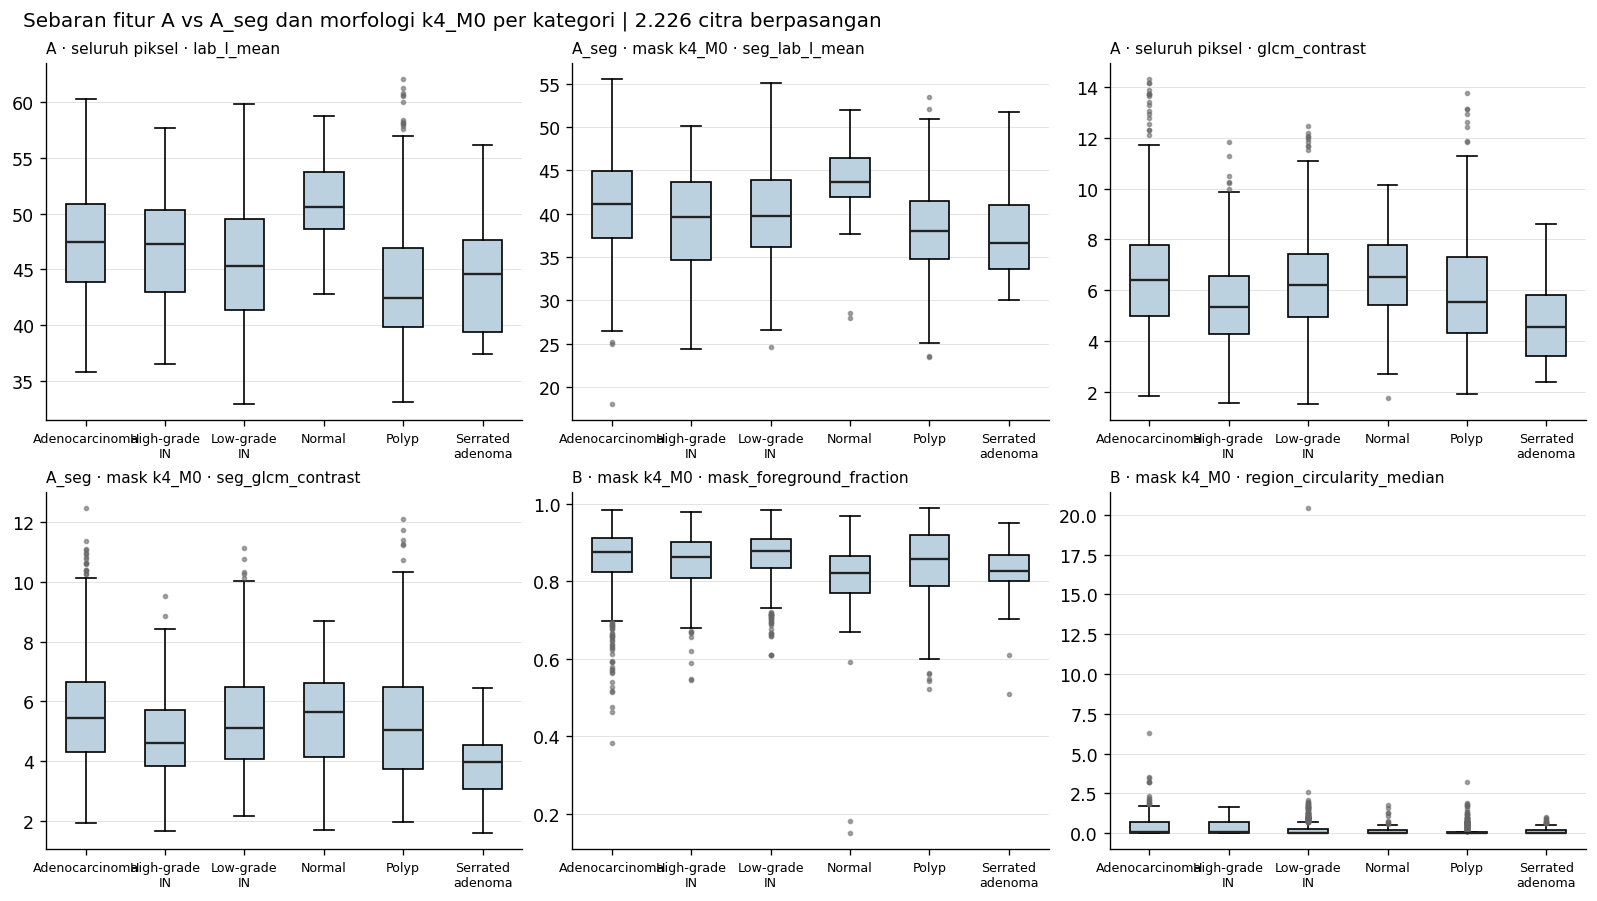

In [6]:
plot_panels = [
    ("A · seluruh piksel", primary, "lab_l_mean"),
    ("A_seg · mask " + SEGMENTED_METHOD, segmented_primary, "seg_lab_l_mean"),
    ("A · seluruh piksel", primary, "glcm_contrast"),
    ("A_seg · mask " + SEGMENTED_METHOD, segmented_primary, "seg_glcm_contrast"),
    ("B · mask " + SEGMENTED_METHOD, primary, "mask_foreground_fraction"),
    ("B · mask " + SEGMENTED_METHOD, primary, "region_circularity_median"),
]

fig, axes = plt.subplots(2, 3, figsize=(13.2, 7.4), layout="constrained")
for axis, (panel_label, frame, feature_name) in zip(axes.ravel(), plot_panels):
    values = [
        frame.loc[frame["category"].eq(category), feature_name].to_numpy()
        for category in EXPECTED_CATEGORIES
    ]
    boxplot = axis.boxplot(
        values,
        tick_labels=[category.replace(" ", "\n") for category in EXPECTED_CATEGORIES],
        patch_artist=True,
        medianprops={"color": "#222222", "linewidth": 1.4},
        flierprops={
            "marker": "o",
            "markersize": 2.4,
            "markerfacecolor": "#666666",
            "markeredgecolor": "#666666",
            "alpha": 0.55,
        },
    )
    for patch in boxplot["boxes"]:
        patch.set_facecolor("#BCD1E0")
    axis.set_title(f"{panel_label} · {feature_name}", loc="left", fontsize=9.2)
    axis.grid(axis="y", color="#E4E4E4", linewidth=0.6)
    axis.tick_params(axis="x", labelsize=7.6)

fig.suptitle(
    f"Sebaran fitur A vs A_seg dan morfologi {SEGMENTED_METHOD} per kategori | 2.226 citra berpasangan",
    fontsize=12,
    x=0.01,
    ha="left",
)
finish_figure(
    fig,
    export_path=(ROOT / "reports/figures/feature_distributions_by_category.png") if EXPORT_FIGURES else None,
)


## 6. Korelasi antar fitur pada set C dan C_seg

Matriks korelasi Pearson membantu mengenali fitur yang sangat redundan sebelum pemodelan hilir. Nilai korelasi tinggi tidak otomatis berarti fitur harus dibuang; keputusan seleksi tetap menjadi bagian dari tahap klasifikasi. Notebook juga menghitung pasangan dengan `|r| >= 0.8` dan korelasi fitur A yang berpasangan dengan A_seg.


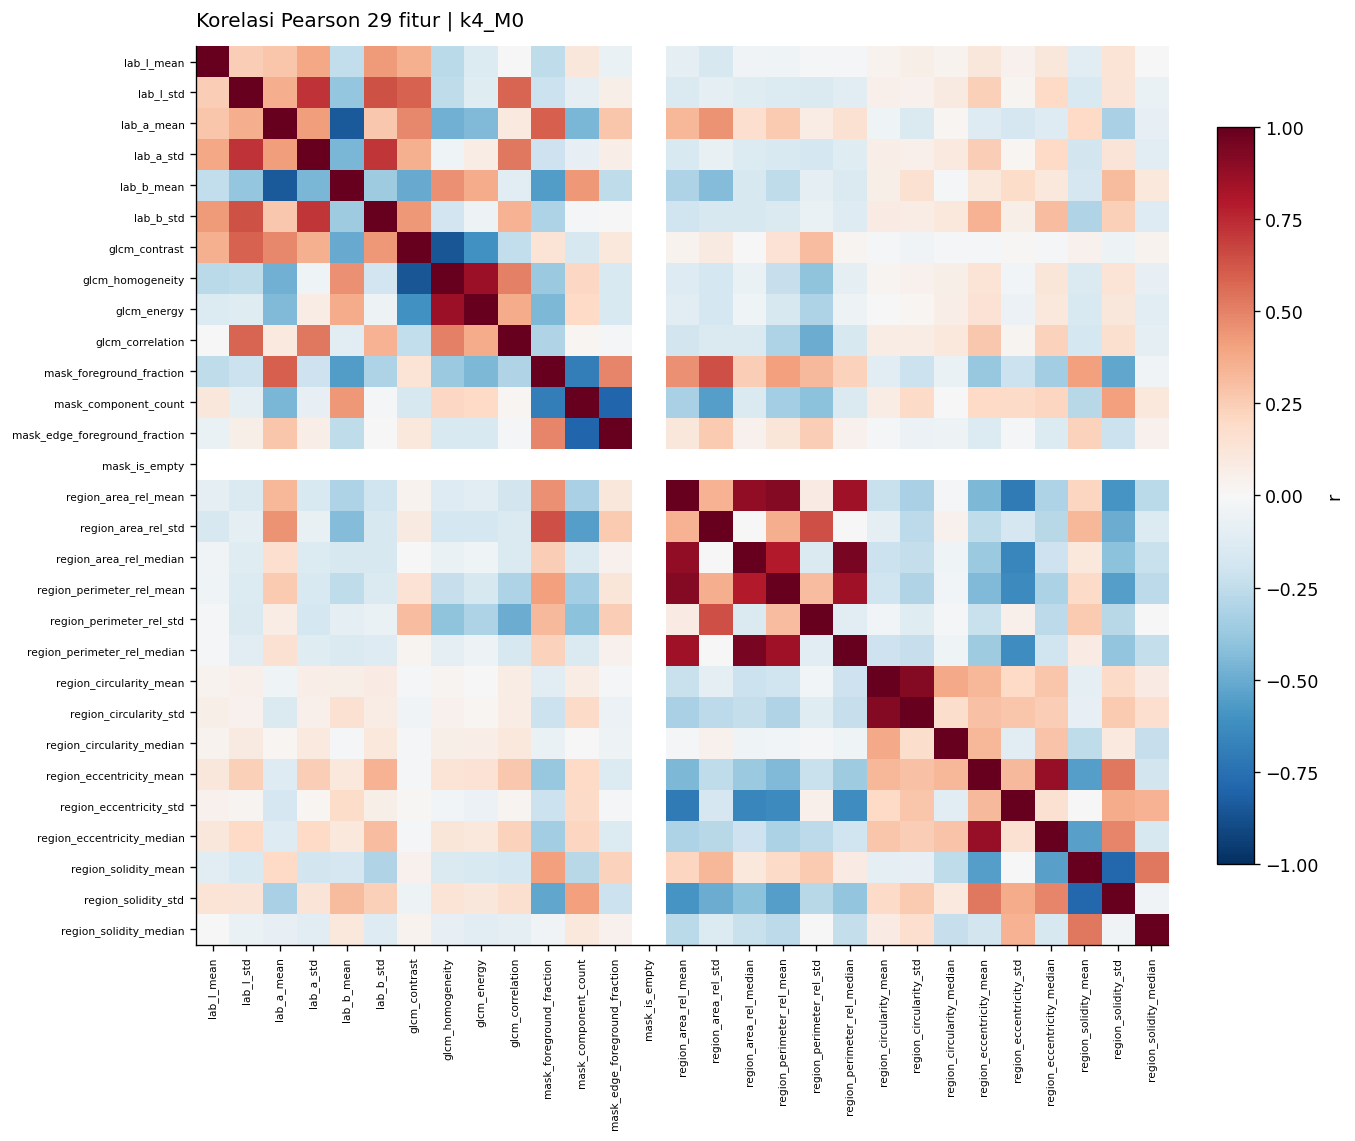

,feature_1,feature_2,r
0,region_area_rel_median,region_perimeter_rel_median,+0.9507
1,region_circularity_mean,region_circularity_std,+0.9183
2,region_area_rel_mean,region_perimeter_rel_mean,+0.9151
3,region_area_rel_mean,region_area_rel_median,+0.8896
4,region_eccentricity_mean,region_eccentricity_median,+0.8677
5,glcm_contrast,glcm_homogeneity,-0.8544
6,glcm_homogeneity,glcm_energy,+0.8535
7,region_area_rel_mean,region_perimeter_rel_median,+0.8458
8,region_perimeter_rel_mean,region_perimeter_rel_median,+0.8452
9,lab_a_mean,lab_b_mean,-0.8374


,feature_1,feature_2,r
0,region_area_rel_median,region_perimeter_rel_median,+0.9507
1,seg_glcm_contrast,seg_glcm_homogeneity,-0.9287
2,region_circularity_mean,region_circularity_std,+0.9183
3,region_area_rel_mean,region_perimeter_rel_mean,+0.9151
4,seg_glcm_homogeneity,seg_glcm_energy,+0.8979
5,region_area_rel_mean,region_area_rel_median,+0.8896
6,region_eccentricity_mean,region_eccentricity_median,+0.8677
7,region_area_rel_mean,region_perimeter_rel_median,+0.8458
8,region_perimeter_rel_mean,region_perimeter_rel_median,+0.8452
9,seg_lab_a_mean,seg_lab_b_mean,-0.8197


,fitur,r_A_A_seg
4,lab_b_mean,+0.9693
2,lab_a_mean,+0.9683
6,glcm_contrast,+0.9500
7,glcm_homogeneity,+0.8644
0,lab_l_mean,+0.7945
1,lab_l_std,+0.7423
5,lab_b_std,+0.6718
8,glcm_energy,+0.6715
9,glcm_correlation,+0.6212
3,lab_a_std,+0.5312


Pasangan |r| >= 0.8: C=10 | C_seg=12 | korelasi A vs A_seg tertinggi=lab_b_mean (+0.9693)


In [7]:
correlation = primary[list(FEATURE_NAMES)].corr(method="pearson")
segmented_correlation = segmented_primary[list(SEGMENTED_FEATURE_NAMES)].corr(method="pearson")

fig_corr, ax_corr = plt.subplots(figsize=(11.2, 9.4), layout="constrained")
image = ax_corr.imshow(correlation.to_numpy(), cmap="RdBu_r", vmin=-1.0, vmax=1.0, aspect="auto")
positions = np.arange(len(FEATURE_NAMES))
ax_corr.set_xticks(positions, FEATURE_NAMES, rotation=90, fontsize=6.4)
ax_corr.set_yticks(positions, FEATURE_NAMES, fontsize=6.4)
ax_corr.set_title(f"Korelasi Pearson 29 fitur | {PRIMARY_METHOD}", loc="left", pad=12)
fig_corr.colorbar(image, ax=ax_corr, shrink=0.82, label="r")
finish_figure(
    fig_corr,
    export_path=(ROOT / "reports/figures/feature_correlation_heatmap.png") if EXPORT_FIGURES else None,
)

def high_correlation_pairs(matrix: pd.DataFrame, threshold: float = 0.8) -> pd.DataFrame:
    rows, cols = np.triu_indices(len(matrix), k=1)
    pairs = pd.DataFrame(
        {
            "feature_1": matrix.index.to_numpy()[rows],
            "feature_2": matrix.columns.to_numpy()[cols],
            "r": matrix.to_numpy()[rows, cols],
        }
    )
    return pairs.loc[pairs["r"].abs().ge(threshold)].sort_values(
        "r", key=lambda series: series.abs(), ascending=False
    ).reset_index(drop=True)

high_pairs = high_correlation_pairs(correlation)
high_pairs_segmented = high_correlation_pairs(segmented_correlation)
matched_correlation = pd.DataFrame(
    {
        "fitur": list(APPEARANCE_FEATURE_NAMES),
        "r_A_A_seg": [
            primary[name].corr(segmented_primary[f"seg_{name}"])
            for name in APPEARANCE_FEATURE_NAMES
        ],
    }
).sort_values("r_A_A_seg", ascending=False)

display(high_pairs.head(10).style.format({"r": "{:+.4f}"}))
display(high_pairs_segmented.head(10).style.format({"r": "{:+.4f}"}))
display(matched_correlation.style.format({"r_A_A_seg": "{:+.4f}"}))
print(
    f"Pasangan |r| >= 0.8: C={len(high_pairs)} | C_seg={len(high_pairs_segmented)} | "
    f"korelasi A vs A_seg tertinggi={matched_correlation.iloc[0]['fitur']} "
    f"({matched_correlation.iloc[0]['r_A_A_seg']:+.4f})"
)


### Temuan 3 — redundansi dan stabilitas korelasi

- Pada set C terdapat **10 pasangan** dengan `|r| >= 0.8`; pada C_seg terdapat **12 pasangan**.
- Pasangan morfologi terkuat sama di kedua set: `region_area_rel_median` vs `region_perimeter_rel_median` (`r = 0.9507`). Ini menunjukkan area dan perimeter komponen membawa informasi yang sangat tumpang tindih.
- Untuk GLCM, `contrast` vs `homogeneity` memiliki `r = −0.8544` pada C dan menguat menjadi `−0.9287` pada C_seg. `homogeneity` vs `energy` juga menguat dari `0.8535` menjadi `0.8979`.
- Korelasi fitur berpasangan A vs A_seg paling tinggi pada `lab_b_mean` (**0.9693**), `lab_a_mean` (**0.9683**), dan `glcm_contrast` (**0.9500**). Sebaliknya, `lab_a_std` (**0.5312**), `glcm_correlation` (**0.6212**), dan `glcm_energy` (**0.6715**) lebih sensitif terhadap masking.
- Implikasi: fitur rerata warna dan kontras cukup stabil, sedangkan fitur variabilitas dan korelasi GLCM membawa informasi tambahan yang bergantung pada batas mask. Seleksi fitur tetap harus divalidasi pada tahap klasifikasi, bukan diputuskan dari korelasi saja.


## 7. Sensitivitas fitur morfologi terhadap komparator segmentasi

Perubahan tahap morfologi (`M0` → `M1`/`M2`) mengubah jumlah komponen, cakupan *foreground*, dan bentuk komponen. Tabel dan diagram berikut membandingkan rerata fitur serta diagnostik mask lintas empat komparator beku, termasuk fraksi komponen berperimeter nol dan selisih cakupan terhadap `k4_M0`.


,mask_foreground_fraction,mask_component_count,region_circularity_median,zero_perimeter_fraction,delta_foreground_vs_k4_M0
otsu_M0,0.5455,200.1298,0.6578,0.3222,-0.3079
otsu_M2,0.5294,69.5508,1.0809,0.0000,-0.3240
k4_M0,0.8534,25.9672,0.2894,0.4919,0.0000
k4_M1,0.8521,5.2332,0.3778,0.0000,-0.0013


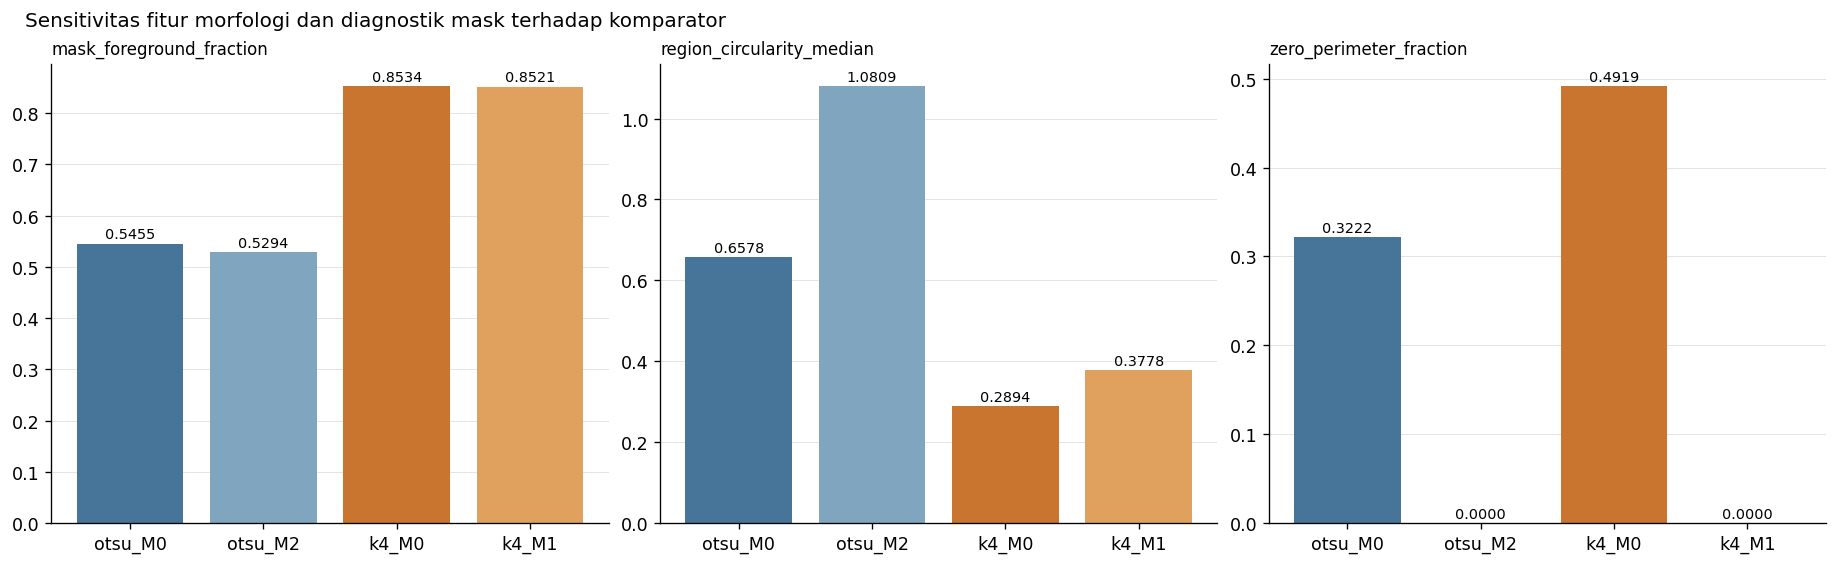

In [8]:
comparator_features = pd.DataFrame(
    {
        method: combined[method][
            [
                "mask_foreground_fraction",
                "mask_component_count",
                "mask_edge_foreground_fraction",
                "region_circularity_median",
                "region_solidity_mean",
            ]
        ].mean()
        for method in FEATURE_METHODS
    }
).T
diagnostic_summary = diagnostics.groupby("method", observed=True).agg(
    empty_masks=("is_empty", "sum"),
    zero_perimeter_components=("zero_perimeter_count", "sum"),
    total_components=("component_count", "sum"),
    border_components=("border_component_count", "sum"),
)
diagnostic_summary["zero_perimeter_fraction"] = (
    diagnostic_summary["zero_perimeter_components"] / diagnostic_summary["total_components"].replace(0, np.nan)
)
comparator_table = pd.concat([comparator_features, diagnostic_summary], axis=1).loc[list(FEATURE_METHODS)]
comparator_table["delta_foreground_vs_k4_M0"] = (
    comparator_table["mask_foreground_fraction"] - comparator_table.loc[PRIMARY_METHOD, "mask_foreground_fraction"]
)
display(
    comparator_table[
        [
            "mask_foreground_fraction",
            "mask_component_count",
            "region_circularity_median",
            "zero_perimeter_fraction",
            "delta_foreground_vs_k4_M0",
        ]
    ].style.format("{:.4f}")
)

fig_methods, axes_methods = plt.subplots(1, 3, figsize=(15.2, 4.6), layout="constrained")
for axis, feature_name in zip(
    axes_methods,
    ["mask_foreground_fraction", "region_circularity_median", "zero_perimeter_fraction"],
):
    values = comparator_table[feature_name].to_numpy()
    bars = axis.bar(FEATURE_METHODS, values, color=["#47759A", "#7FA6BE", "#C97530", "#E0A15E"])
    for bar, value in zip(bars, values):
        axis.text(
            bar.get_x() + bar.get_width() / 2.0,
            value + 0.005 * max(float(values.max()), 1e-9),
            f"{value:.4f}",
            ha="center",
            va="bottom",
            fontsize=8.6,
        )
    axis.set_title(feature_name, loc="left", fontsize=10)
    axis.grid(axis="y", color="#E4E4E4", linewidth=0.6)

fig_methods.suptitle("Sensitivitas fitur morfologi dan diagnostik mask terhadap komparator", fontsize=12, x=0.01, ha="left")
finish_figure(
    fig_methods,
    export_path=(ROOT / "reports/figures/feature_method_sensitivity.png") if EXPORT_FIGURES else None,
)


### Temuan 4 — sensitivitas morfologi dan risiko `k4_M0`

- `k4_M0` memiliki rerata `mask_foreground_fraction` **0,8534** dan `mask_edge_foreground_fraction` **0,9913**; mask hampir menutupi seluruh bidang dan hampir seluruh *foreground* menyentuh tepi. Ini berbeda tajam dari `otsu_M0` yang lebih konservatif (**0,5455**).
- `k4_M0` juga memiliki **28.433 dari 57.803 komponen** dengan perimeter nol (**49,19%**). `otsu_M0` memiliki fraksi lebih rendah (**32,22%**), sedangkan `otsu_M2` dan `k4_M1` tidak memiliki komponen berperimeter nol.
- Konsekuensinya, fitur morfologi `k4_M0`—terutama `circularity` dan ukuran per komponen—harus dibaca sebagai deskripsi mask yang sangat luas, bukan bukti bahwa batas objek presisi. Temuan ini memperkuat alasan A_seg/C_seg disimpan terpisah dan tiga komparator lain tetap dipakai untuk sensitivitas.


## 8. Uji paritas: hitung ulang sampel dari citra dan artefak beku

Sebanyak dua sampel per split dihitung ulang melalui `build_feature_tables` dan `build_segmented_feature_tables`, lalu dibandingkan dengan CSV kanonik. Uji ini memastikan artefak A/B/C serta A_seg/C_seg benar-benar dapat direproduksi dari citra RGB, konfigurasi Otsu, model K-means, dan aturan morfologi yang sama.


In [9]:
parity_ids = []
for split_name in ("train", "val", "test"):
    parity_ids.extend(
        split_df.loc[split_df["split"].eq(split_name), "sample_id"]
        .head(PARITY_SAMPLES_PER_SPLIT)
        .tolist()
    )

parity_tables = build_feature_tables(
    ROOT,
    methods=FEATURE_METHODS,
    splits=("train", "val", "test"),
    data_root_override=DATA_ROOT_OVERRIDE,
    sample_ids=parity_ids,
)
validate_feature_table(parity_tables.appearance, feature_names=APPEARANCE_FEATURE_NAMES, require_method=False)

parity_rows = []
for method in FEATURE_METHODS:
    stored = combined[method].set_index("sample_id").loc[parity_ids, list(FEATURE_NAMES)]
    recomputed = parity_tables.combined[method].set_index("sample_id").loc[parity_ids, list(FEATURE_NAMES)]
    max_abs_diff = float(np.abs(stored.to_numpy() - recomputed.to_numpy()).max())
    parity_rows.append(
        {"method": method, "n_samples": len(parity_ids), "max_abs_difference": max_abs_diff}
    )

parity_report = pd.DataFrame(parity_rows)
display(parity_report.style.format({"max_abs_difference": "{:.3e}"}))
assert parity_report["max_abs_difference"].max() < 1e-12

segmented_parity_tables = build_segmented_feature_tables(
    ROOT,
    method=SEGMENTED_METHOD,
    splits=("train", "val", "test"),
    data_root_override=DATA_ROOT_OVERRIDE,
    sample_ids=parity_ids,
)
validate_feature_table(
    segmented_parity_tables.appearance,
    feature_names=SEGMENTED_APPEARANCE_FEATURE_NAMES,
    require_method=False,
)
segmented_stored = segmented_combined.set_index("sample_id").loc[parity_ids, list(SEGMENTED_FEATURE_NAMES)]
segmented_recomputed = segmented_parity_tables.combined.set_index("sample_id").loc[parity_ids, list(SEGMENTED_FEATURE_NAMES)]
segmented_parity_report = pd.DataFrame(
    [
        {
            "method": SEGMENTED_METHOD,
            "n_samples": len(parity_ids),
            "max_abs_difference": float(
                np.abs(segmented_stored.to_numpy() - segmented_recomputed.to_numpy()).max()
            ),
        }
    ]
)
display(segmented_parity_report.style.format({"max_abs_difference": "{:.3e}"}))
assert segmented_parity_report["max_abs_difference"].max() < 1e-12
print("Paritas terverifikasi: fitur A/B/C dan A_seg/C_seg identik hingga presisi mesin.")


,method,n_samples,max_abs_difference
0,otsu_M0,6,7.105e-15
1,otsu_M2,6,7.105e-15
2,k4_M0,6,7.105e-15
3,k4_M1,6,7.105e-15


,method,n_samples,max_abs_difference
0,k4_M0,6,7.105e-15


Paritas terverifikasi: fitur A/B/C dan A_seg/C_seg identik hingga presisi mesin.


## 9. Inventaris artefak dan provenance

Tabel berikut mencatat berkas masukan yang dilindungi beserta ukuran dan awalan SHA-256. Checksum penuh diverifikasi ulang pada sel terakhir untuk memastikan notebook tidak mengubah artefak eksperimen. Artefak A_seg/C_seg diperlakukan sama seperti artefak kanonik: tidak ditimpa dan ikut masuk hash closure.


In [10]:
artifact_inventory = pd.DataFrame(
    [
        {
            "artefak": path.relative_to(ROOT).as_posix(),
            "bytes": path.stat().st_size,
            "sha256_prefix": input_hashes_before[name][:20],
        }
        for name, path in protected_files.items()
    ]
)
display(artifact_inventory)

display(
    pd.DataFrame(
        [
            {"komponen": "split_sha256", "nilai": manifest["split_sha256"]},
            {"komponen": "primary_method", "nilai": manifest["primary_method"]},
            {"komponen": "jumlah metode", "nilai": len(manifest["methods"])},
            {"komponen": "jumlah sampel train", "nilai": manifest["sample_counts"].get("train", 0)},
            {"komponen": "jumlah sampel val", "nilai": manifest["sample_counts"].get("val", 0)},
            {"komponen": "jumlah sampel test", "nilai": manifest["sample_counts"].get("test", 0)},
        ]
    )
)

display(
    pd.DataFrame(
        [
            {
                "manifest": "feature_manifest.json",
                "schema": manifest["schema_version"],
                "sumber_mask": "4 komparator (A/GLCM seluruh piksel + B mask)",
                "train": manifest["sample_counts"].get("train", 0),
                "val": manifest["sample_counts"].get("val", 0),
                "test": manifest["sample_counts"].get("test", 0),
            },
            {
                "manifest": f"feature_manifest_segmented_{SEGMENTED_METHOD}.json",
                "schema": segmented_manifest["schema_version"],
                "sumber_mask": f"A_seg/C_seg dari mask {SEGMENTED_METHOD}",
                "train": segmented_manifest["sample_counts"].get("train", 0),
                "val": segmented_manifest["sample_counts"].get("val", 0),
                "test": segmented_manifest["sample_counts"].get("test", 0),
            },
        ]
    )
)


,artefak,bytes,sha256_prefix
0,data/metadata/split_manifest.csv,575716,ceeba8e282f77cdb78a9
1,configs/otsu_raw.json,466,dcd8b0867f50f10912fc
2,results/otsu_morph_val.csv,81575,17f24293a33b1fefe78a
3,results/kmeans_morph_val.csv,530758,8a30172c8d2d90b453e7
4,results/kmeans_morph_val_run.json,1066,5ecd034b88d84ecab74b
5,results/features/feature_manifest.json,3695,9b19f8013c3514f64146
6,results/features/appearance.csv,557455,4d7b2c8b8a3c86ff710d
7,results/features/morphology_diagnostics.csv,902500,4ddcaa970774d9b3ebf5
8,results/features/feature_manifest_segmented_k4...,3793,ed6a5373c971a495a4b7
9,results/features/appearance_segmented_k4_M0.csv,555336,41a3d127debae126788a


,komponen,nilai
0,split_sha256,ceeba8e282f77cdb78a9675618b3dcb6729fbc2339e2d1...
1,primary_method,k4_M0
2,jumlah metode,4
3,jumlah sampel train,1535
4,jumlah sampel val,372
5,jumlah sampel test,319


,manifest,schema,sumber_mask,train,val,test
0,feature_manifest.json,feature-extraction-v1,4 komparator (A/GLCM seluruh piksel + B mask),1535,372,319
1,feature_manifest_segmented_k4_M0.json,segmented-feature-extraction-v1,A_seg/C_seg dari mask k4_M0,1535,372,319


## 10. Checklist kesesuaian laporan dan kontrak tahap 07

Laporan `PROGRESS.docx` belum diedit pada tahap ini, tetapi isi yang perlu diselaraskan sudah teridentifikasi:

| Butir | Kondisi saat ini | Tindakan yang diperlukan |
|---|---|---|
| Jumlah citra | Laporan menulis 2.280 | Koreksi menjadi **2.228 citra** pada audit filesystem, dengan **2.226 pasangan** yang dipakai analisis |
| Jumlah mask | Laporan menulis 2.228 | Koreksi menjadi **2.226 mask**; sebutkan dua citra tanpa mask dan kelompok low-grade 639/637 |
| Subbagian ekstraksi fitur | Masih kosong | Isi dengan definisi A (10), A_seg (10, `k4_M0`), B (19), C (29), dan C_seg (29) |
| Asal fitur | Ada kalimat yang bertentangan: “citra asli” vs “area segmentasi” | Nyatakan eksplisit: A dari seluruh piksel; A_seg dari piksel mask prediksi `k4_M0`; B dari mask prediksi |
| Konfigurasi utama | Belum tegas di laporan | Nyatakan `k4_M0` sebagai konfigurasi utama; `otsu_M0`, `otsu_M2`, `k4_M1` hanya sensitivitas |
| Split | Belum konsisten disebut | Tulis 1.535 train / 372 val / 319 test dan checksum manifest |
| Satuan analisis | Belum dijelaskan | Gunakan klasifikasi **image-level**; sebutkan 353 grup dan 74 grup multi-kategori; validasi harus *group-aware* |
| Artefak | Belum dirinci | Cantumkan nama CSV/manifest lama dan A_seg, serta penegasan tidak ada pembacaan *reference mask* |

Kontrak tahap 07: gunakan `sample_id`, `category`, `group_id`, `split`, dan 29 fitur dari `k4_M0`; jangan memakai `test` untuk pemilihan model, *scaling*, atau *tuning*; A_seg/C_seg dipakai sebagai analisis sensitivitas sampai ada evaluasi model yang membenarkan penggantian.


## Kesimpulan dan serah-terima

- **Fitur kanonik tersedia** untuk 2.226 citra × 4 komparator: set A (10), set B (19), dan set C (29). **A_seg/C_seg** tersedia untuk `k4_M0` dan disimpan sebagai artefak terpisah.
- **Konfigurasi utama** untuk klasifikasi hilir adalah `k4_M0`; tiga komparator lain disimpan untuk analisis sensitivitas. `k4_M0` memiliki cakupan *foreground* sangat luas dan 49,19% komponen berperimeter nol, sehingga fitur morfologinya perlu dibaca dengan hati-hati.
- **A → A_seg** mengubah rerata dan variabilitas warna/GLCM secara sistematis; `eta^2` train sedikit lebih tinggi untuk A_seg, tetapi peringkat fitur berubah. A_seg belum boleh dianggap pengganti A tanpa evaluasi model.
- **Paritas** antara CSV kanonik dan perhitungan ulang dari citra terbukti hingga `1e-12` untuk A/B/C dan A_seg/C_seg.
- **Langkah berikutnya (handoff):** klasifikasi SVM A/B/C memakai kolom `sample_id`, `category`, `group_id`, `split`, dan 29 fitur `k4_M0`; evaluasi **image-level** dan *group-aware*. Pemilihan model, *scaling*, dan evaluasi akhir **tidak** dilakukan di notebook ini.


In [11]:
input_hashes_after = {name: sha256_bytes(path) for name, path in protected_files.items()}
assert input_hashes_after == input_hashes_before, "Artefak input berubah saat notebook dieksekusi."
paired_ids = set(split_df.loc[split_df["pair_status"].eq("paired"), "sample_id"])
assert set(appearance["sample_id"]) == paired_ids
assert set(segmented_appearance["sample_id"]) == paired_ids
assert set(segmented_combined["sample_id"]) == paired_ids
print(
    "Selesai: 2.226 citra berpasangan, 4 komparator, set fitur 10/19/29, "
    f"plus A_seg/C_seg {SEGMENTED_METHOD}; seluruh artefak input dan tabel fitur tetap identik."
)


Selesai: 2.226 citra berpasangan, 4 komparator, set fitur 10/19/29, plus A_seg/C_seg k4_M0; seluruh artefak input dan tabel fitur tetap identik.
